In [1]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "baxtiyorbotiraliyev/insects",output_dir="/content/insects"
)

print("Dataset path:", dataset_path)
print("Contents:", os.listdir(dataset_path))

Dataset path: /kaggle/input/datasets/baxtiyorbotiraliyev/insects
Contents: ['dataset']


In [2]:
from pathlib import Path
from collections import Counter

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_files = [
    p for p in Path(dataset_path).rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Total images:", len(image_files))

class_counts = Counter(
    p.parent.name for p in image_files
)

print("\nClass distribution:")

for class_name, count in sorted(class_counts.items()):
    print(f"{class_name}: {count}")

Total images: 112693

Class distribution:
adristyrannus: 311
aleurocanthus spiniferus: 690
alfalfa plant bug: 656
alfalfa seed chalcid: 185
alfalfa weevil: 524
ampelophaga: 764
ant: 1924
aphids: 6200
apolygus lucorum: 381
armyworm: 3530
asiatic rice borer: 1053
bactrocera tsuneonis: 168
bee: 2923
beet fly: 104
beetle: 2562
black cutworm: 854
blister beetle: 1897
bollworm: 36
brevipoalpus lewisi McGregor: 79
brown plant hopper: 834
butterfly: 1390
catterpillar: 1041
cerodonta denticornis: 137
ceroplastes rubens: 258
chayon: 525
chlumetia transversa: 305
chrysomphalus aonidum: 225
cicadella viridis: 1279
cicadellidae: 5740
corn borer: 1698
dacus dorsalis(Hendel): 439
dasineura sp: 505
deporaus marginatus Pascoe: 210
dragonfly: 677
earthworm: 797
earwig: 1092
erythroneura apicalis: 71
fall armyworm: 1784
flax budworm: 1066
flea beetle: 789
fly: 1809
grain spreader thrips: 173
grasshopper: 6298
grub: 860
icerya purchasi Maskell: 722
kolorado: 100
ladybug: 1207
large cutworm: 491
lawana imi

In [3]:
import pandas as pd

# Create a DataFrame from the existing image_files list
# We convert PosixPath objects to strings, and grab the parent directory's name as the class label
df = pd.DataFrame({
    'filepath': [str(p) for p in image_files],
    'label': [p.parent.name for p in image_files]
})

# Display the DataFrame info and first few rows
print(f"Created DataFrame with {len(df)} rows.")
display(df.head())


Created DataFrame with 112693 rows.


,filepath,label
0,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,adristyrannus
1,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,adristyrannus
2,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,adristyrannus
3,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,adristyrannus
4,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,adristyrannus


In [4]:
import pandas as pd

# Select six classes
selected_classes = [
    "ant",
    "bee",
    "beetle",
    "butterfly",
    "grasshopper",
    "ladybug"
]

# Number of images per class
SAMPLES_PER_CLASS = 1200

# Select and balance the dataset
balanced_df = (
    df[df["label"].isin(selected_classes)]
    .groupby("label", group_keys=False)
    .sample(
        n=SAMPLES_PER_CLASS,
        random_state=42
    )
    .reset_index(drop=True)
)

# Shuffle dataset
balanced_df = balanced_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Total selected images:", len(balanced_df))

print("\nClass distribution:")
print(balanced_df["label"].value_counts())

Total selected images: 7200

Class distribution:
label
beetle         1200
butterfly      1200
bee            1200
ant            1200
ladybug        1200
grasshopper    1200
Name: count, dtype: int64


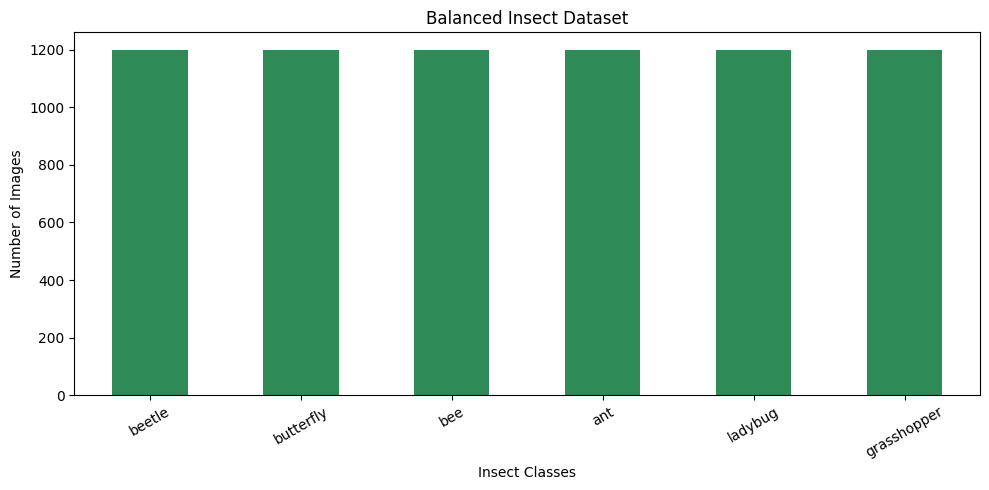

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

balanced_df["label"].value_counts().plot(
    kind="bar",
    color="seagreen"
)

plt.title("Balanced Insect Dataset")
plt.xlabel("Insect Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [6]:
df.sample(10)

,filepath,label
79623,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,penthaleus major
35433,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,cicadella viridis
63871,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,limacodidae
40678,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,corn borer
90505,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,spider
17737,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,aphids
58115,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,leaf beetle
105780,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,flax budworm
10983,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,wire worm
86649,/kaggle/input/datasets/baxtiyorbotiraliyev/ins...,salurnis marginella Guerr


In [7]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    balanced_df,
    test_size=0.30,
    stratify=balanced_df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training: 5040
Validation: 1080
Testing: 1080

Training distribution:
label
butterfly      840
grasshopper    840
beetle         840
ladybug        840
ant            840
bee            840
Name: count, dtype: int64

Validation distribution:
label
butterfly      180
ant            180
grasshopper    180
bee            180
beetle         180
ladybug        180
Name: count, dtype: int64

Testing distribution:
label
ant            180
beetle         180
ladybug        180
butterfly      180
bee            180
grasshopper    180
Name: count, dtype: int64


In [8]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS = 25

class_names = sorted(balanced_df["label"].unique())
NUM_CLASSES = len(class_names)

class_to_index = {
    name: index
    for index, name in enumerate(class_names)
}

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Classes: ['ant', 'bee', 'beetle', 'butterfly', 'grasshopper', 'ladybug']
Number of classes: 6


In [9]:
def load_image(filepath, label):

    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    image = image / 255.0

    return image, label


def create_dataset(dataframe, training=False):

    paths = dataframe["filepath"].values

    labels = dataframe["label"].map(
        class_to_index
    ).values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training, validation and testing datasets are ready!")

Training, validation and testing datasets are ready!


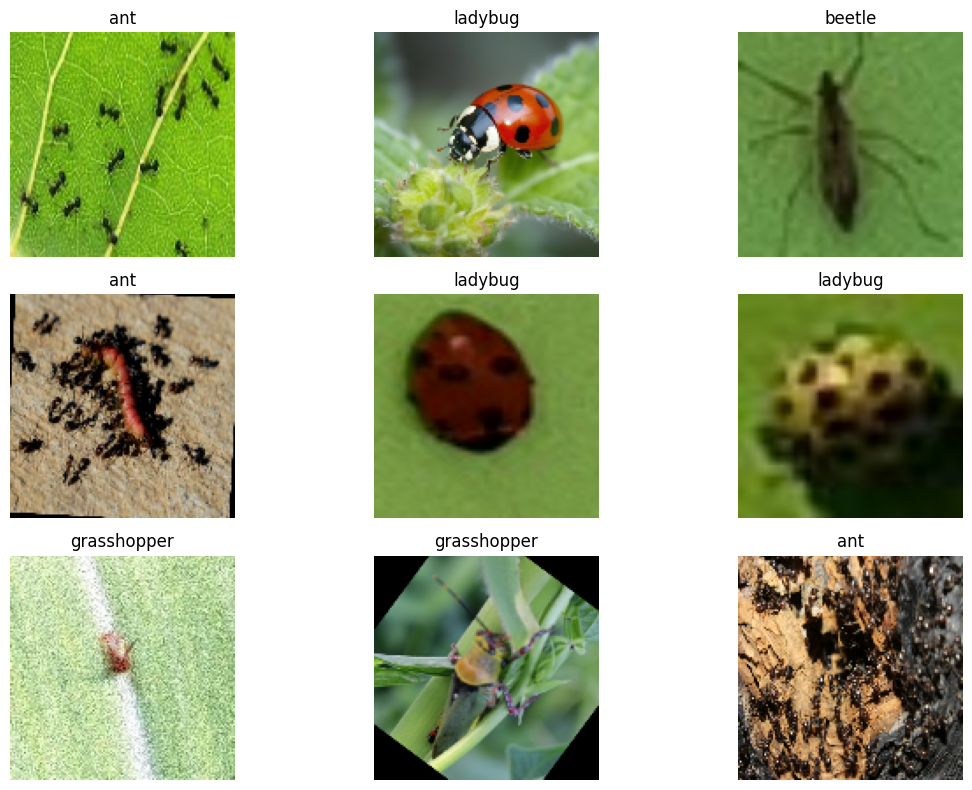

In [10]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        plt.title(class_names[labels[i].numpy()])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
model = models.Sequential([

    layers.Input(shape=(128, 128, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Fully connected layers
    layers.Flatten(),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.5),

    # Output layer
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,454 (16.36 MB)

 Trainable params: 4,288,454 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [13]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/25


E0000 00:00:1795119590.537467     142 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


157/158 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.2724 - loss: 1.8432

E0000 00:00:1795119673.096730     143 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


158/158 ━━━━━━━━━━━━━━━━━━━━ 108s 631ms/step - accuracy: 0.3484 - loss: 1.6113 - val_accuracy: 0.4954 - val_loss: 1.2714
Epoch 2/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.5329 - loss: 1.2357 - val_accuracy: 0.6037 - val_loss: 1.0865
Epoch 3/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.6087 - loss: 1.0718 - val_accuracy: 0.6741 - val_loss: 0.9292
Epoch 4/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - accuracy: 0.6538 - loss: 0.9423 - val_accuracy: 0.6509 - val_loss: 0.9559
Epoch 5/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 55ms/step - accuracy: 0.7008 - loss: 0.8127 - val_accuracy: 0.7148 - val_loss: 0.7732
Epoch 6/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.7456 - loss: 0.6934 - val_accuracy: 0.7352 - val_loss: 0.7285
Epoch 7/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.7659 - loss: 0.6264 - val_accuracy: 0.7306 - val_loss: 0.7700
Epoch 8/25
158/158 ━━━━━━━━━━━━━━━━━━━━ 8s 54ms/step - accuracy: 0.8010 - loss: 0.5471 - val_accuracy: 0.

## Plot accuracy and loss curves

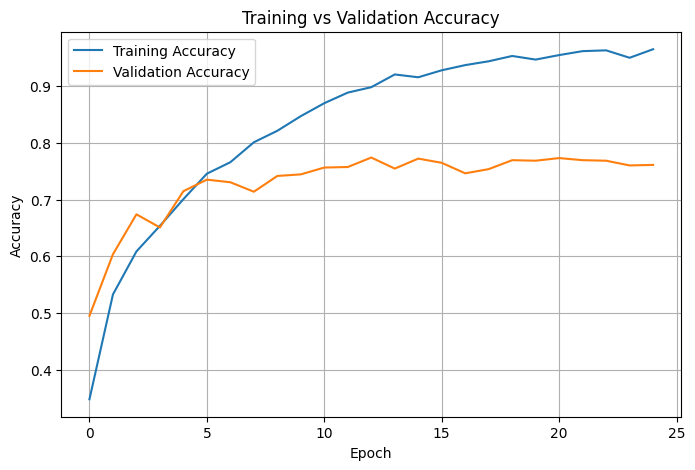

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

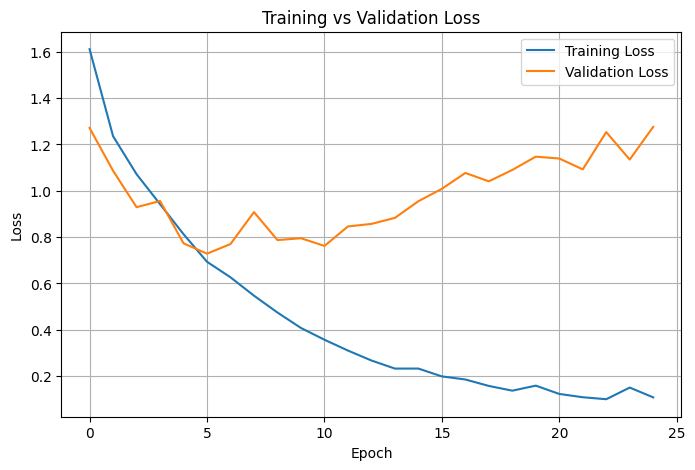

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

## Evaluate final accuracy

In [16]:
train_loss, train_accuracy = model.evaluate(
    train_ds,
    verbose=0
)

val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=0
)

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=0
)

print("FINAL RESULTS")
print("=" * 35)

print(f"Training Accuracy:   {train_accuracy * 100:.2f}%")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Testing Accuracy:    {test_accuracy * 100:.2f}%")

FINAL RESULTS
Training Accuracy:   99.58%
Validation Accuracy: 76.11%
Testing Accuracy:    76.02%


## Confusion matrix

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step


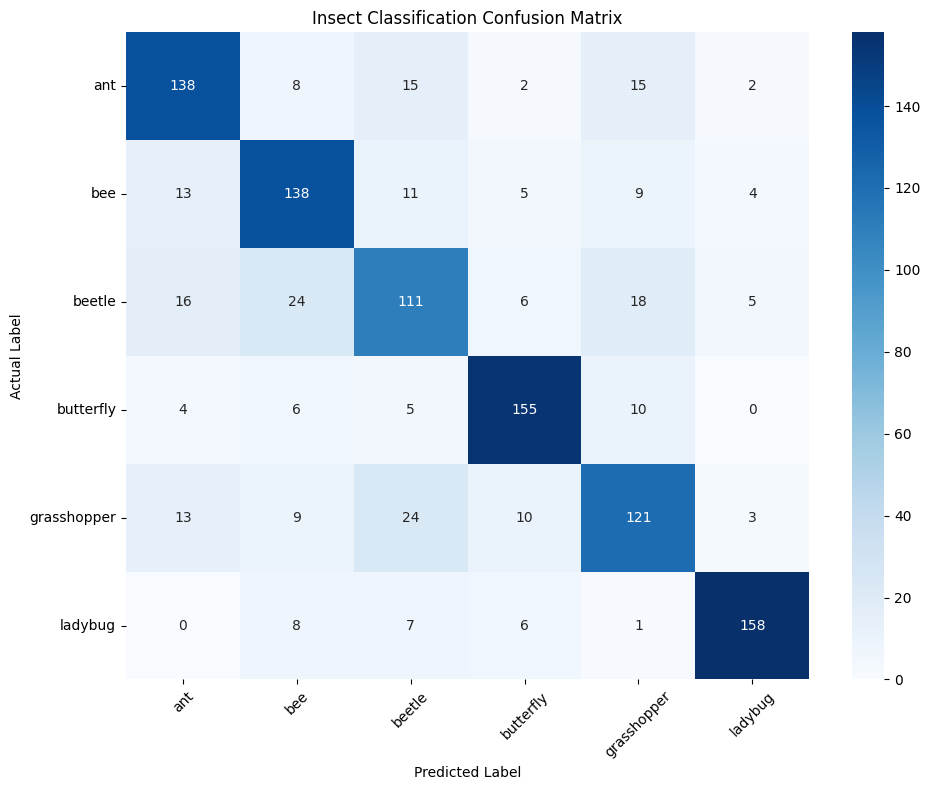

              precision    recall  f1-score   support

         ant       0.75      0.77      0.76       180
         bee       0.72      0.77      0.74       180
      beetle       0.64      0.62      0.63       180
   butterfly       0.84      0.86      0.85       180
 grasshopper       0.70      0.67      0.68       180
     ladybug       0.92      0.88      0.90       180

    accuracy                           0.76      1080
   macro avg       0.76      0.76      0.76      1080
weighted avg       0.76      0.76      0.76      1080



In [17]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Insect Classification Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

## Save trained model

In [18]:
model.save("insect_classification_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


## Cross validation

In [19]:

from sklearn.model_selection import StratifiedKFold, train_test_split

# Combine training and validation data
cv_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

# Shuffle the combined dataset
cv_df = cv_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print("Cross-validation dataset:", len(cv_df))
print("Independent test dataset:", len(test_df))

print("\nClass distribution:")
print(cv_df["label"].value_counts())


Cross-validation dataset: 6120
Independent test dataset: 1080

Class distribution:
label
ladybug        1020
bee            1020
grasshopper    1020
ant            1020
beetle         1020
butterfly      1020
Name: count, dtype: int64


## Improved CNN architecture

Our previous architecture had approximately 4.29 million parameters. Most were in the Flatten-to-Dense connection.

We'll replace Flatten with GlobalAveragePooling2D, which significantly reduces the number of parameters.

We'll also add:
- Batch normalization.
- Data augmentation.
- L2 regularization.
- Configurable dropout.
- Configurable learning rate.

In [20]:

import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam

def build_improved_cnn(
    learning_rate=0.001,
    dropout_rate=0.4,
    l2_strength=0.0001
):

    model = models.Sequential([

        layers.Input(shape=(128, 128, 3)),

        # Data augmentation
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.10),
        layers.RandomZoom(0.10),

        # Block 1
        layers.Conv2D(
            32, (3, 3),
            padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        # Block 2
        layers.Conv2D(
            64, (3, 3),
            padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        # Block 3
        layers.Conv2D(
            128, (3, 3),
            padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),

        # Reduce parameters
        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),

        layers.Dropout(dropout_rate),

        layers.Dense(
            NUM_CLASSES,
            activation="softmax"
        )
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Create a sample model
improved_model = build_improved_cnn()

improved_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,430 (435.27 KB)

 Trainable params: 110,982 (433.52 KB)

 Non-trainable params: 448 (1.75 KB)

## Hyperparameter tuning

In [21]:

from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import pandas as pd

# Hyperparameter configurations
configurations = [
    {
        "name": "A",
        "learning_rate": 0.001,
        "dropout_rate": 0.3,
        "l2_strength": 0.0001
    },
    {
        "name": "B",
        "learning_rate": 0.001,
        "dropout_rate": 0.5,
        "l2_strength": 0.001
    },
    {
        "name": "C",
        "learning_rate": 0.0003,
        "dropout_rate": 0.3,
        "l2_strength": 0.001
    },
    {
        "name": "D",
        "learning_rate": 0.0003,
        "dropout_rate": 0.5,
        "l2_strength": 0.0001
    }
]

# Stratified 5-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X = cv_df["filepath"].values
y = cv_df["label"].values

cv_results = []

for config in configurations:

    print("\nTesting configuration:", config["name"])

    fold_accuracies = []

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y), start=1
    ):

        print(f"  Fold {fold}/5")

        # Create fold datasets
        fold_train_df = cv_df.iloc[train_idx].reset_index(drop=True)
        fold_val_df = cv_df.iloc[val_idx].reset_index(drop=True)

        fold_train_ds = create_dataset(
            fold_train_df,
            training=True
        )

        fold_val_ds = create_dataset(
            fold_val_df
        )

        # Clear previous model
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(42 + fold)

        # Build a fresh model
        cv_model = build_improved_cnn(
            learning_rate=config["learning_rate"],
            dropout_rate=config["dropout_rate"],
            l2_strength=config["l2_strength"]
        )

        callbacks = [
            EarlyStopping(
                monitor="val_loss",
                patience=3,
                restore_best_weights=True
            ),

            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=2,
                min_lr=1e-6
            )
        ]

        # Train
        fold_history = cv_model.fit(
            fold_train_ds,
            validation_data=fold_val_ds,
            epochs=15,
            callbacks=callbacks,
            verbose=0
        )

        # Evaluate best restored weights
        _, fold_accuracy = cv_model.evaluate(
            fold_val_ds,
            verbose=0
        )

        fold_accuracies.append(fold_accuracy)

        print(f"    Validation accuracy: {fold_accuracy * 100:.2f}%")

        del cv_model, fold_train_ds, fold_val_ds
        tf.keras.backend.clear_session()

    # Calculate average performance
    mean_accuracy = np.mean(fold_accuracies)
    std_accuracy = np.std(fold_accuracies)

    cv_results.append({
        "Configuration": config["name"],
        "Learning Rate": config["learning_rate"],
        "Dropout": config["dropout_rate"],
        "L2": config["l2_strength"],
        "Mean CV Accuracy": mean_accuracy,
        "Std CV Accuracy": std_accuracy
    })

    print(
        f"Mean CV accuracy: {mean_accuracy * 100:.2f}% "
        f"+/- {std_accuracy * 100:.2f}%"
    )

# Display results
cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

print("\nFINAL HYPERPARAMETER RESULTS")
display(cv_results_df)



Testing configuration: A
  Fold 1/5
    Validation accuracy: 55.64%
  Fold 2/5
    Validation accuracy: 59.48%
  Fold 3/5
    Validation accuracy: 57.60%
  Fold 4/5
    Validation accuracy: 63.24%
  Fold 5/5
    Validation accuracy: 61.52%
Mean CV accuracy: 59.49% +/- 2.70%

Testing configuration: B
  Fold 1/5
    Validation accuracy: 51.55%
  Fold 2/5
    Validation accuracy: 52.21%
  Fold 3/5
    Validation accuracy: 50.16%
  Fold 4/5
    Validation accuracy: 51.55%
  Fold 5/5
    Validation accuracy: 57.03%
Mean CV accuracy: 52.50% +/- 2.36%

Testing configuration: C
  Fold 1/5
    Validation accuracy: 55.23%
  Fold 2/5
    Validation accuracy: 55.15%
  Fold 3/5
    Validation accuracy: 61.44%
  Fold 4/5
    Validation accuracy: 58.09%
  Fold 5/5
    Validation accuracy: 57.76%
Mean CV accuracy: 57.53% +/- 2.31%

Testing configuration: D
  Fold 1/5
    Validation accuracy: 54.08%
  Fold 2/5
    Validation accuracy: 51.88%
  Fold 3/5
    Validation accuracy: 56.86%
  Fold 4/5
    Va

,Configuration,Learning Rate,Dropout,L2,Mean CV Accuracy,Std CV Accuracy
0,A,0.0010,0.3,0.0001,0.594935,0.027044
2,C,0.0003,0.3,0.0010,0.575327,0.023070
3,D,0.0003,0.5,0.0001,0.549020,0.021953
1,B,0.0010,0.5,0.0010,0.525000,0.023592


## Select the best hyperparameters

In [22]:

best_config_name = cv_results_df.iloc[0]["Configuration"]

best_config = next(
    config for config in configurations
    if config["name"] == best_config_name
)

print("BEST CONFIGURATION")
print("-------------------------")
print(best_config)

print(
    "\nMean CV Accuracy:",
    f"{cv_results_df.iloc[0]['Mean CV Accuracy'] * 100:.2f}%"
)

print(
    "CV Standard Deviation:",
    f"{cv_results_df.iloc[0]['Std CV Accuracy'] * 100:.2f}%"
)


BEST CONFIGURATION
-------------------------
{'name': 'A', 'learning_rate': 0.001, 'dropout_rate': 0.3, 'l2_strength': 0.0001}

Mean CV Accuracy: 59.49%
CV Standard Deviation: 2.70%


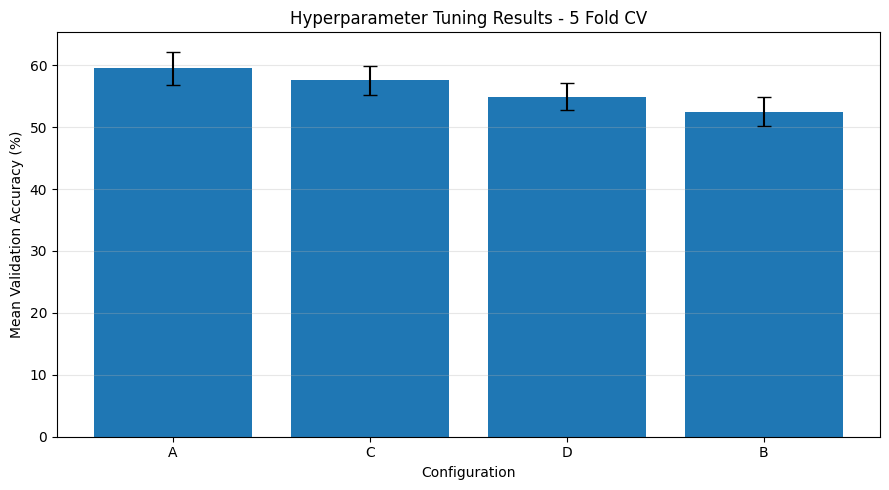

In [23]:

plt.figure(figsize=(9, 5))

plt.bar(
    cv_results_df["Configuration"],
    cv_results_df["Mean CV Accuracy"] * 100,
    yerr=cv_results_df["Std CV Accuracy"] * 100,
    capsize=5
)

plt.title("Hyperparameter Tuning Results - 5 Fold CV")
plt.xlabel("Configuration")
plt.ylabel("Mean Validation Accuracy (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Train the final optimized CNN

In [24]:

# Split development data for final training
final_train_df, final_val_df = train_test_split(
    cv_df,
    test_size=0.10,
    random_state=42,
    stratify=cv_df["label"]
)

final_train_ds = create_dataset(
    final_train_df,
    training=True
)

final_val_ds = create_dataset(
    final_val_df
)

# Build optimized model
final_model = build_improved_cnn(
    learning_rate=best_config["learning_rate"],
    dropout_rate=best_config["dropout_rate"],
    l2_strength=best_config["l2_strength"]
)

final_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# Train final model
final_history = final_model.fit(
    final_train_ds,
    validation_data=final_val_ds,
    epochs=30,
    callbacks=final_callbacks
)


Epoch 1/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.4430 - loss: 1.5005 - val_accuracy: 0.2876 - val_loss: 1.7168 - learning_rate: 0.0010
Epoch 2/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.5310 - loss: 1.2961 - val_accuracy: 0.4248 - val_loss: 1.5362 - learning_rate: 0.0010
Epoch 3/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.5594 - loss: 1.2308 - val_accuracy: 0.5359 - val_loss: 1.2503 - learning_rate: 0.0010
Epoch 4/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.5737 - loss: 1.1874 - val_accuracy: 0.4379 - val_loss: 1.5910 - learning_rate: 0.0010
Epoch 5/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.5873 - loss: 1.1492 - val_accuracy: 0.4036 - val_loss: 2.0691 - learning_rate: 0.0010
Epoch 6/30
172/173 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5999 - loss: 1.1145
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.5999 - los

## Plot optimized model accuracy and loss

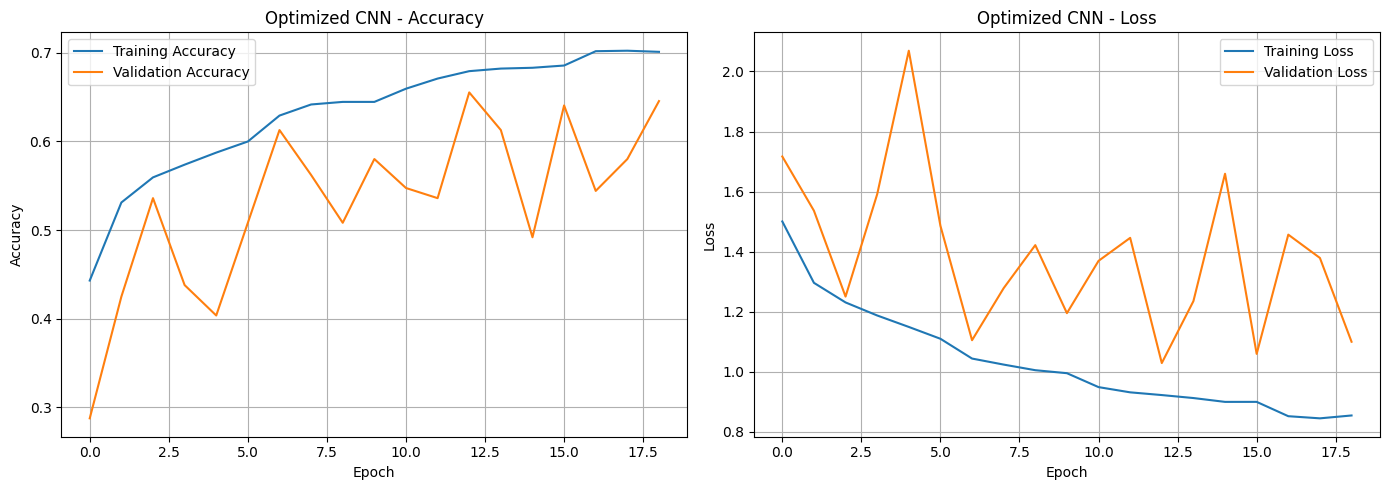

In [25]:
plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    final_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    final_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Optimized CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    final_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    final_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Optimized CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Final evaluation on the independent test set

In [26]:
# Evaluate optimized model
final_train_loss, final_train_acc = final_model.evaluate(
    final_train_ds,
    verbose=0
)

final_val_loss, final_val_acc = final_model.evaluate(
    final_val_ds,
    verbose=0
)

final_test_loss, final_test_acc = final_model.evaluate(
    test_ds,
    verbose=0
)

# Results table
final_results = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Accuracy (%)": [
        final_train_acc * 100,
        final_val_acc * 100,
        final_test_acc * 100
    ],
    "Loss": [
        final_train_loss,
        final_val_loss,
        final_test_loss
    ]
})

display(final_results.round(4))

print(
    f"5-Fold CV Accuracy: "
    f"{cv_results_df.iloc[0]['Mean CV Accuracy'] * 100:.2f}%"
)

,Dataset,Accuracy (%),Loss
0,Training,65.2869,0.9895
1,Validation,65.5229,1.0289
2,Testing,63.7963,1.0568


5-Fold CV Accuracy: 59.49%


## Optimized model confusion matrix

34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step


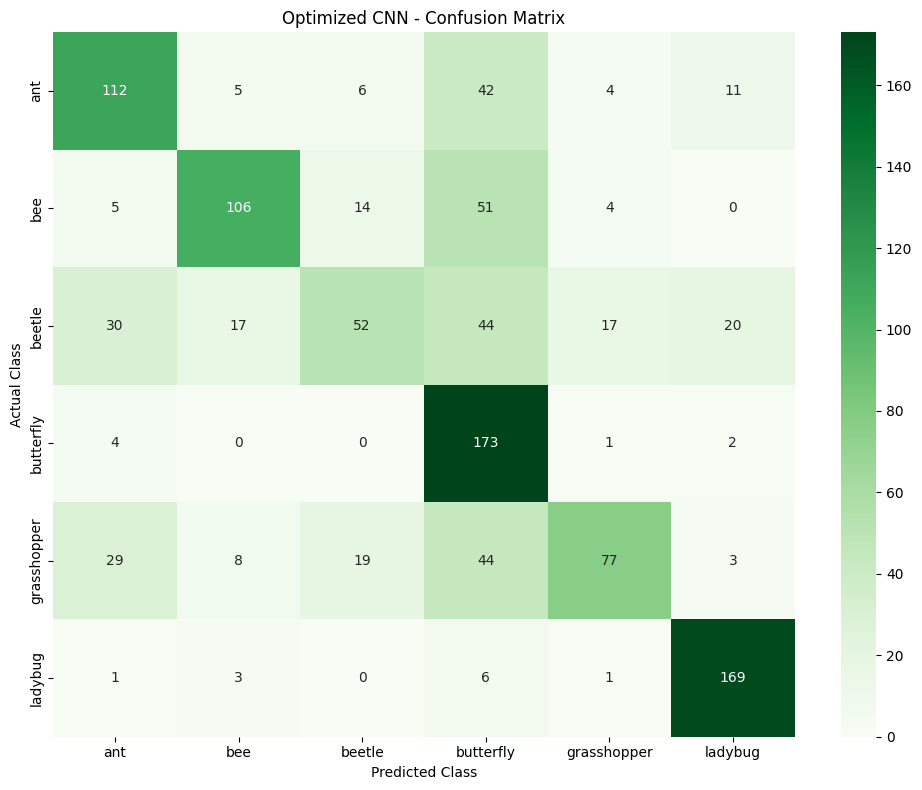

              precision    recall  f1-score   support

         ant       0.62      0.62      0.62       180
         bee       0.76      0.59      0.66       180
      beetle       0.57      0.29      0.38       180
   butterfly       0.48      0.96      0.64       180
 grasshopper       0.74      0.43      0.54       180
     ladybug       0.82      0.94      0.88       180

    accuracy                           0.64      1080
   macro avg       0.67      0.64      0.62      1080
weighted avg       0.67      0.64      0.62      1080



In [27]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_ds
])

y_prob = final_model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Optimized CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

## Compare baseline CNN vs optimized CNN

,Model,Test Accuracy (%)
0,Baseline CNN,76.018518
1,Optimized CNN,63.796294


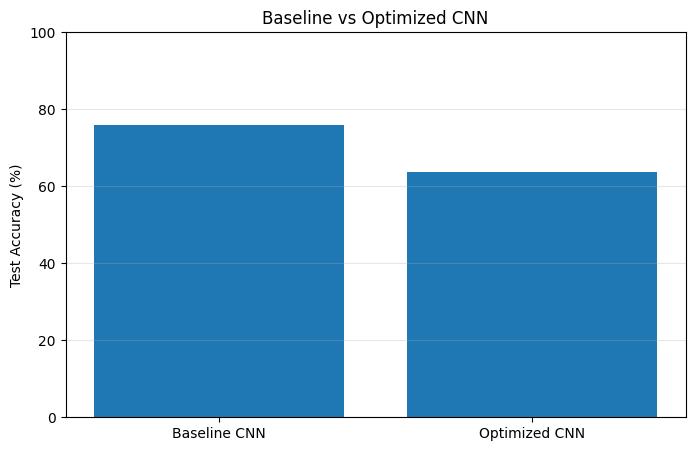

In [28]:
comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Optimized CNN"
    ],
    "Test Accuracy (%)": [
        test_accuracy * 100,
        final_test_acc * 100
    ]
})

display(comparison)

plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Model"],
    comparison["Test Accuracy (%)"]
)

plt.title("Baseline vs Optimized CNN")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.show()

## Build CNN version 3

In [29]:

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam

def build_v3_cnn(
    learning_rate=0.0005,
    dropout_rate=0.3,
    l2_strength=0.0001
):

    model = models.Sequential([

        layers.Input(shape=(128, 128, 3)),

        # Moderate data augmentation
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.05),

        # Block 1
        layers.Conv2D(
            32, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Block 2
        layers.Conv2D(
            64, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Block 3
        layers.Conv2D(
            128, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Block 4
        layers.Conv2D(
            256, 3, padding="same",
            kernel_regularizer=regularizers.l2(l2_strength)
        ),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(),

        # Classification
        layers.GlobalAveragePooling2D(),

        layers.Dense(128, activation="relu"),

        layers.Dropout(dropout_rate),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


## Train version 3

In [30]:

tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(42)

model_v3 = build_v3_cnn()

callbacks_v3 = [

    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.000001,
        verbose=1
    )
]

history_v3 = model_v3.fit(
    final_train_ds,
    validation_data=final_val_ds,
    epochs=30,
    callbacks=callbacks_v3
)


Epoch 1/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 14s 60ms/step - accuracy: 0.4512 - loss: 1.4799 - val_accuracy: 0.1748 - val_loss: 2.0026 - learning_rate: 5.0000e-04
Epoch 2/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.5432 - loss: 1.2547 - val_accuracy: 0.3611 - val_loss: 1.6226 - learning_rate: 5.0000e-04
Epoch 3/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.5882 - loss: 1.1529 - val_accuracy: 0.5196 - val_loss: 1.2959 - learning_rate: 5.0000e-04
Epoch 4/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.6151 - loss: 1.0849 - val_accuracy: 0.6258 - val_loss: 1.0506 - learning_rate: 5.0000e-04
Epoch 5/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.6322 - loss: 1.0171 - val_accuracy: 0.5376 - val_loss: 1.4296 - learning_rate: 5.0000e-04
Epoch 6/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.6478 - loss: 0.9887 - val_accuracy: 0.4918 - val_loss: 1.4163 - learning_rate: 5.0000e-04
Epoch 7/30
173/173 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step

In [32]:
train_loss_v3, train_acc_v3 = model_v3.evaluate(
    final_train_ds, verbose=0
)

val_loss_v3, val_acc_v3 = model_v3.evaluate(
    final_val_ds, verbose=0
)

test_loss_v3, test_acc_v3 = model_v3.evaluate(
    test_ds, verbose=0
)

print("CNN VERSION 3 RESULTS")
print("=" * 35)

print(f"Training Accuracy:   {train_acc_v3 * 100:.2f}%")
print(f"Validation Accuracy: {val_acc_v3 * 100:.2f}%")
print(f"Testing Accuracy:    {test_acc_v3 * 100:.2f}%")

CNN VERSION 3 RESULTS
Training Accuracy:   78.63%
Validation Accuracy: 76.63%
Testing Accuracy:    75.09%


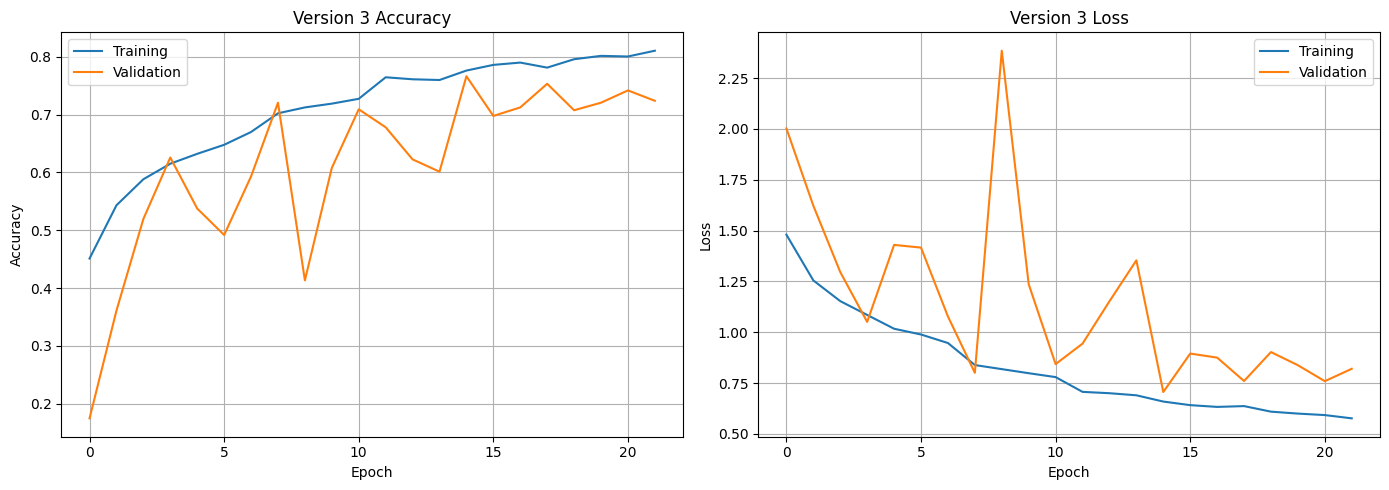

In [34]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

plt.plot(history_v3.history["accuracy"], label="Training")
plt.plot(history_v3.history["val_accuracy"], label="Validation")

plt.title("Version 3 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(history_v3.history["loss"], label="Training")
plt.plot(history_v3.history["val_loss"], label="Validation")

plt.title("Version 3 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [36]:
print("Best validation accuracy:")
print(max(history.history["val_accuracy"]) * 100)

print("\nBest epoch:")
print(np.argmax(history.history["val_accuracy"]) + 1)

print("\nFinal model evaluation:")
print(final_results.round(4))

Best validation accuracy:
77.40740776062012

Best epoch:
13

Final model evaluation:
      Dataset  Accuracy (%)    Loss
0    Training       65.2869  0.9895
1  Validation       65.5229  1.0289
2     Testing       63.7963  1.0568


# Final experiment: MobileNetV2 transfer learning
## Update image size and recreate datasets

In [37]:
IMG_SIZE = 160
BATCH_SIZE = 32

# Recreate datasets at the new image size
final_train_ds = create_dataset(final_train_df, training=True)
final_val_ds = create_dataset(final_val_df)
test_ds = create_dataset(test_df)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Classes: ['ant', 'bee', 'beetle', 'butterfly', 'grasshopper', 'ladybug']
Number of classes: 6


## Build the MobileNetV2 model

In [38]:
import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model

# Data augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.05)
])

# Pretrained CNN
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build complete model
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = data_augmentation(inputs)

# Convert pixel range from [0, 1] to [-1, 1]
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.0001)
)(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

final_model = Model(inputs, outputs)

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,726 (9.24 MB)

 Trainable params: 164,742 (643.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Train the classification head

In [39]:
def get_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True,
            verbose=1
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6,
            verbose=1
        )
    ]

history_stage1 = final_model.fit(
    final_train_ds,
    validation_data=final_val_ds,
    epochs=15,
    callbacks=get_callbacks()
)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 16s 64ms/step - accuracy: 0.8295 - loss: 0.5269 - val_accuracy: 0.9199 - val_loss: 0.2554 - learning_rate: 0.0010
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9176 - loss: 0.2766 - val_accuracy: 0.9412 - val_loss: 0.1992 - learning_rate: 0.0010
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.9277 - loss: 0.2393 - val_accuracy: 0.9428 - val_loss: 0.2138 - learning_rate: 0.0010
Epoch 4/15
172/173 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9292 - loss: 0.2239
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9345 - loss: 0.2135 - val_accuracy: 0.9379 - val_loss: 0.2079 - learning_rate: 0.0010
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.9517 - loss: 0.1627 - val_accuracy: 0.9477 - val_loss: 0.1886 - learning_rate: 5.0000e-04
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9519 -

## Fine-tune the last 30 layers

In [41]:
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a very small learning rate
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_stage2 = final_model.fit(
    final_train_ds,
    validation_data=final_val_ds,
    epochs=15,
    callbacks=get_callbacks()
)

Epoch 1/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 17s 65ms/step - accuracy: 0.9822 - loss: 0.0859 - val_accuracy: 0.9510 - val_loss: 0.1739 - learning_rate: 1.0000e-05
Epoch 2/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.9791 - loss: 0.0864 - val_accuracy: 0.9641 - val_loss: 0.1634 - learning_rate: 1.0000e-05
Epoch 3/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.9828 - loss: 0.0790 - val_accuracy: 0.9559 - val_loss: 0.1864 - learning_rate: 1.0000e-05
Epoch 4/15
171/173 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.9873 - loss: 0.0731
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.9846 - loss: 0.0743 - val_accuracy: 0.9510 - val_loss: 0.1703 - learning_rate: 1.0000e-05
Epoch 5/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.9858 - loss: 0.0697 - val_accuracy: 0.9559 - val_loss: 0.1646 - learning_rate: 5.0000e-06
Epoch 6/15
173/173 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - ac

## Evaluate the final model

In [42]:
train_loss, train_acc = final_model.evaluate(
    final_train_ds, verbose=0
)

val_loss, val_acc = final_model.evaluate(
    final_val_ds, verbose=0
)

test_loss, test_acc = final_model.evaluate(
    test_ds, verbose=0
)

print("FINAL MOBILENETV2 RESULTS")
print("=" * 40)
print(f"Training Accuracy:   {train_acc * 100:.2f}%")
print(f"Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Testing Accuracy:    {test_acc * 100:.2f}%")

FINAL MOBILENETV2 RESULTS
Training Accuracy:   99.55%
Validation Accuracy: 96.24%
Testing Accuracy:    96.67%


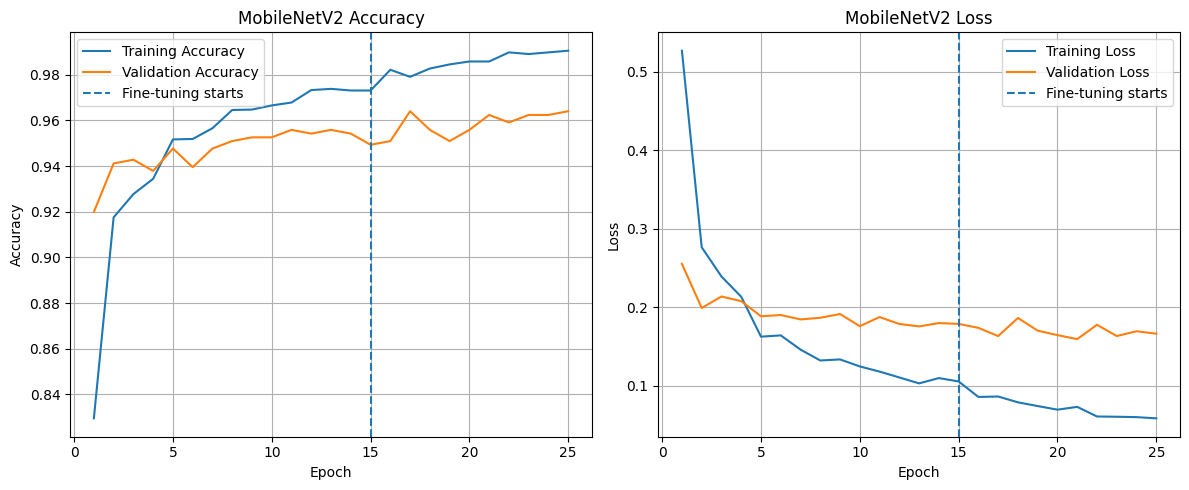

In [48]:
import matplotlib.pyplot as plt

accuracy = (
    history_stage1.history["accuracy"] +
    history_stage2.history["accuracy"]
)

val_accuracy = (
    history_stage1.history["val_accuracy"] +
    history_stage2.history["val_accuracy"]
)

loss = (
    history_stage1.history["loss"] +
    history_stage2.history["loss"]
)

val_loss = (
    history_stage1.history["val_loss"] +
    history_stage2.history["val_loss"]
)

epochs = range(1, len(accuracy) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, accuracy, label="Training Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.axvline(
    len(history_stage1.history["accuracy"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, label="Training Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.axvline(
    len(history_stage1.history["loss"]),
    linestyle="--",
    label="Fine-tuning starts"
)
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [51]:
final_model.save("/kaggle/working/final_insect_classifier.keras")
print("Final model saved successfully!")

Final model saved successfully!
